# 06 · Asking your discipline's questions of a place

The same layers answer very different questions. Each section below starts from a question a researcher in one
field might ask about Quetta, turns it into a query, and says what the answer can and cannot support. They are
starting points for fieldwork and archives, not substitutes for them.

| Field | Question |
|---|---|
| Sociology | Are schools and clinics shared evenly among the city's people? |
| Gender studies | Which bus stops can be reached along busy, shop-lined streets, and how many live near them? |
| Labour studies | Where is paid work, and how far is it from where people live? |
| Anthropology, religion | How are places of worship spread, and what share of people live within earshot of one? |
| History | What do street and place names remember? |
| Literature | Mapping the places named in a text |
| Urban studies | Which parts of the city are dense, built-up and poorly served? |
| Political geography | Where are extraction, roads and violence, and who lives near them? (province) |

*Running this in Google Colab?* The next cell installs the few libraries Colab lacks (about a minute). Notebooks
04-07 read files made by 01 and 02: run those first in the same session, or keep the `data` folder on Google Drive.

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "osmnx", "overturemaps", "mapclassify", "esda", "libpysal", "folium", "plotly"], check=True)

In [2]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, osmnx as ox, matplotlib.pyplot as plt
DATA, CRS = Path("data"), 32642
area = gpd.read_file(DATA / "boundary.gpkg").to_crs(CRS)
grid = gpd.read_file(DATA / "grid_500m.gpkg")
poi = gpd.read_file(DATA / "places.gpkg").to_crs(CRS)
edges = ox.graph_to_gdfs(ox.load_graphml(DATA / "walk.graphml"), nodes=False).to_crs(CRS)
lived = grid[grid.people > 50].copy()

## Sociology: are services shared evenly?
A *concentration curve* sorts cells from best to worst served and plots the share of people against the share of
services. The *Gini coefficient* summarises it: 0 = perfectly even, 1 = all in one place.

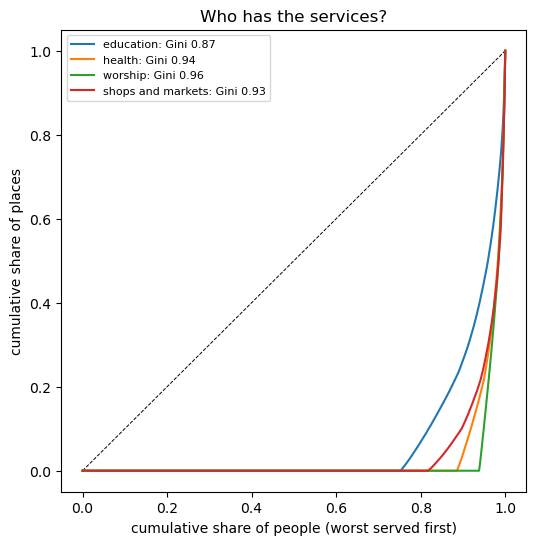

In [3]:
def gini_share(people, services):
    """Gini of services per person across cells, weighted by people."""
    o = np.argsort(services / np.maximum(people, 1))
    p, s = np.cumsum(people[o]) / people.sum(), np.cumsum(services[o]) / max(services.sum(), 1)
    return 1 - 2 * np.trapezoid(s, p), p, s
fig, ax = plt.subplots(figsize=(6, 6)); ax.plot([0, 1], [0, 1], "k--", lw=.7)
for cat in ["education", "health", "worship", "shops and markets"]:
    n = gpd.sjoin(poi[poi.category == cat][["geometry"]], lived, predicate="within").groupby("cell").size().reindex(lived.cell).fillna(0).values
    g, p, s = gini_share(lived.people.values, n)
    ax.plot(np.r_[0, p], np.r_[0, s], label=f"{cat}: Gini {g:.2f}")
ax.set(xlabel="cumulative share of people (worst served first)", ylabel="cumulative share of places", title="Who has the services?"); ax.legend(fontsize=8);

**Can support:** a description of spatial inequality in *mapped* services. **Cannot:** quality, cost, who is
admitted, or services missing from OSM (private tutors, informal clinics). Pair with household surveys.

## Gender studies: reachable public transport along "active" streets
Many studies of women's mobility find that busy, shop-lined, well-lit streets feel safer than empty ones. Here an
*active street* is a segment with at least 3 shops within 50 m. Which bus stops are on active streets, and how many
people live within 400 m of one? (Better data on lighting, harassment reports or walk-along interviews would
change the definition; the method stays the same.)

In [4]:
shops = poi[poi.category == "shops and markets"]
e = edges[["geometry"]].reset_index(drop=True)
e["shops_50m"] = gpd.sjoin(shops[["geometry"]], e.assign(geometry=e.buffer(50)), predicate="within").groupby("index_right").size().reindex(e.index).fillna(0).values
e["active"] = e.shops_50m >= 3
stops = poi[poi.category == "public transport"]
near = gpd.sjoin_nearest(stops[["geometry"]], e[["active", "geometry"]], max_distance=30, how="left")
active_stops = stops.loc[near[near.active.fillna(False).astype(bool)].index.unique()]
print(f"{e.active.mean():.0%} of street segments are 'active'; {len(active_stops)} of {len(stops)} mapped stops lie on one")
c = lived.copy(); c["geometry"] = lived.centroid
for name, s in [("any stop", stops), ("a stop on an active street", active_stops)]:
    within = c.within(s.buffer(400).union_all()) if len(s) else pd.Series(False, index=c.index)
    print(f"people within 400 m of {name}: {lived.people[within.values].sum() / lived.people.sum():.0%}")

1% of street segments are 'active'; 6 of 72 mapped stops lie on one
people within 400 m of any stop: 16%
people within 400 m of a stop on an active street: 2%


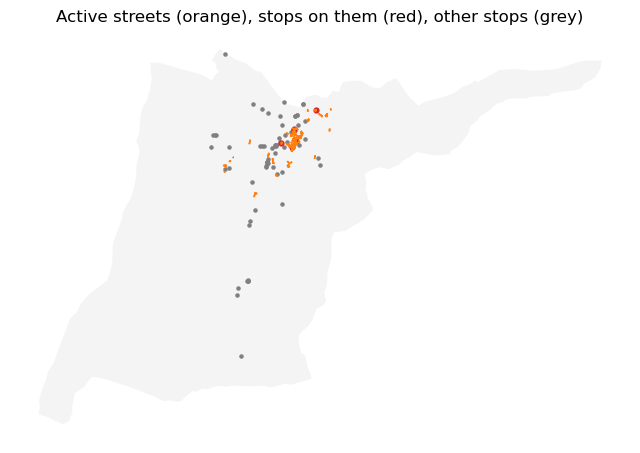

In [5]:
ax = area.plot(color="#f4f4f4", figsize=(8, 8))
e[e.active].plot(ax=ax, color="C1", lw=1.2, label="active street"); stops.plot(ax=ax, color="grey", markersize=5)
active_stops.plot(ax=ax, color="C3", markersize=12); ax.set_axis_off(); ax.set_title("Active streets (orange), stops on them (red), other stops (grey)");

**Reading:** only about 1% of street segments have 3 or more mapped shops within 50 m, and 6 of 72 mapped stops
lie on such a street: 16% of people live within 400 m of any mapped stop, 2% of one on an active street.
Bus stops in Quetta are sparsely mapped (most transport is informal: rickshaws, vans, *chingchi*). A low number
here is a finding about the *map*, which is itself worth reporting.

## Labour studies: where is work, and how far from home?
Workplaces in OSM: industrial land, works, offices, markets. Distance from each populated cell to the nearest
workplace, weighted by people:

In [6]:
work = poi[poi.category.isin(["work", "shops and markets"])]
d = gpd.sjoin_nearest(c[["cell", "people", "geometry"]], work[["geometry"]], distance_col="m").drop_duplicates("cell")
wq = np.average(d.m, weights=d.people)
print(f"people-weighted mean straight-line distance to the nearest mapped workplace: {wq:,.0f} m")
print(d.assign(km=pd.cut(d.m, [0, 250, 500, 1000, 2000, 1e9], labels=["<250 m", "250-500", "0.5-1 km", "1-2 km", ">2 km"])).groupby("km").people.sum().div(d.people.sum()).round(2))

people-weighted mean straight-line distance to the nearest mapped workplace: 700 m
km
<250 m      0.28
250-500     0.22
0.5-1 km    0.25
1-2 km      0.21
>2 km       0.04
Name: people, dtype: float32


**Next steps a labour researcher might take:** add brick kilns, coal-mine access roads and labour *addas* (daily
wage pick-up points) from fieldwork; compare with census occupation tables; map commuting routes from interviews.

## Anthropology and religion: places of worship and earshot
A call to prayer carries several hundred metres. What share of people live within 300 m of a mapped mosque,
church, temple or gurdwara? `religion` tags (where present) show diversity.

In [7]:
w = poi[poi.category == "worship"]
print(w.get("religion", pd.Series(dtype=str)).fillna("not tagged").value_counts().head(6))
print(f"people within 300 m of a mapped place of worship: {lived.people[c.within(w.buffer(300).union_all()).values].sum() / lived.people.sum():.0%}")

religion
muslim        24
not tagged    23
hindu          2
christian      1
Name: count, dtype: int64
people within 300 m of a mapped place of worship: 7%


**Reading:** only about 50 places of worship are mapped, and about 7% of people live within 300 m of one. Quetta
has hundreds of mosques, plus churches, temples and imambargahs, so the number shows how little of the city's
religious life is on the open map, not how far people live from it. A researcher would map them in the field (an
OSM mapping day is a good research method) before measuring anything.

## History: what do names remember?
Street and place names record rulers, saints, tribes, colonial officers and events. Grouping names by their words
is a first step; OSM's `name:etymology:wikidata` tag (where mappers added it) links a name to the person it honours.

In [8]:
names = pd.Series(edges["name"].dropna().astype(str).unique()) if "name" in edges else pd.Series(dtype=str)
names = names.str.replace(r"[\[\]']", "", regex=True)
words = names.str.split(r"[\s,]+").explode().str.strip()
words = words[words.str.len() > 2]
common = words[~words.str.lower().isin(["road", "street", "the", "and", "bazar", "bazaar", "lane", "chowk"])].value_counts().head(20)
print(len(names), "named streets"); common

355 named streets


روڈ         32
Colony      18
Town        14
Area        14
Muhammad    14
Khan        13
No.         11
Sariab       8
Killi        8
Ismail       7
Haji         7
Ali          6
Kasi         5
Malik        5
Abdul        5
Stop         5
Din          5
Mengal       5
شاہراہ       5
Mir          5
Name: count, dtype: int64

Colonial names (e.g. after British officers), Baloch, Pashtun and Hazara names, and post-1947 renamings sit side by
side. A historian would continue with gazetteers, colonial-era maps (for example the 1890s Survey of India sheets)
overlaid as a layer in `folium` (`folium.raster_layers.ImageOverlay` for a georeferenced scan).

## Literature: mapping the places named in a text
Geocode place names from a novel, memoir or poem, then map them. The list below is illustrative; replace it with
names extracted from your text (by hand or with a named-entity tagger).

In [9]:
text_places = ["Quetta Railway Station", "Liaquat Bazar", "Hanna Lake", "Jinnah Road", "Quetta Cantonment", "Mari Abad"]
rows = []
for p in text_places:
    try:
        g = ox.geocode(f"{p}, Quetta, Pakistan"); rows.append({"place": p, "lat": g[0], "lon": g[1]})
    except Exception:
        rows.append({"place": p, "lat": np.nan, "lon": np.nan})
tp = pd.DataFrame(rows); print(tp)
tp = tp.dropna()
if len(tp):
    m = gpd.GeoDataFrame(tp, geometry=gpd.points_from_xy(tp.lon, tp.lat), crs=4326).explore(marker_kwds={"radius": 7}, color="crimson", tooltip=["place"], tiles="Esri.WorldGrayCanvas")
    import folium
    folium.PolyLine(list(zip(tp.lat, tp.lon)), color="crimson", weight=2, dash_array="5").add_to(m)
m if len(tp) else "no places found"

                    place        lat        lon
0  Quetta Railway Station  30.191627  67.000756
1           Liaquat Bazar  30.191704  67.014432
2              Hanna Lake  30.255951  67.099677
3             Jinnah Road  30.202007  67.015070
4       Quetta Cantonment  30.226697  67.045621
5               Mari Abad        NaN        NaN


Order the places as they appear in the text to draw a character's route; colour them by chapter; add quotations
as pop-ups. Places that cannot be geocoded are part of the reading: invented, renamed or lost.

## Urban studies: dense, built-up and poorly served

In [10]:
lived["flag"] = (lived.people >= lived.people.quantile(.75)) & (lived.min_to_clinic >= 15)
print(f"{lived.flag.sum()} cells are in the densest quarter and >= 15 min walk from a clinic, home to {lived.people[lived.flag].sum():,.0f} people")
lived.to_crs(4326).explore(column="flag", cmap=["#dddddd", "#c0392b"], tooltip=["people", "min_to_clinic", "buildings"], tiles="Esri.WorldGrayCanvas", style_kwds={"weight": 0, "fillOpacity": .6})

88 cells are in the densest quarter and >= 15 min walk from a clinic, home to 121,516 people


## Political geography: the province (data from notebook 02)
Three questions often asked about Balochistan, each as a query. They describe patterns; explaining them needs
history, interviews and documents.

**Where is extraction, and who lives there?** Mapped mines, quarries, wells and works per district against
population and urban share.

In [11]:
dist = gpd.read_file(DATA / "bal_districts.gpkg").to_crs(CRS)
ext = gpd.read_file(DATA / "bal_extraction.gpkg").to_crs(CRS)
roads = gpd.read_file(DATA / "bal_roads.gpkg").to_crs(CRS)
dist["extraction_sites"] = gpd.sjoin(ext, dist[["adm2_name", "geometry"]], predicate="within").groupby("adm2_name").size().reindex(dist.adm2_name).fillna(0).values
dist[["adm2_name", "extraction_sites", "pop2017", "urban_share", "events"]].sort_values("extraction_sites", ascending=False).head(10).round(2)

,adm2_name,extraction_sites,pop2017,urban_share,events
16,Lasbela,93.0,574292.0,0.49,12.0
8,Kachhi,23.0,237030.0,0.15,26.0
12,Khuzdar,21.0,802207.0,0.35,39.0
3,Dera Bugti,19.0,312603.0,0.32,88.0
4,Gwadar,18.0,263514.0,0.61,59.0
2,Chagai,17.0,226008.0,0.07,14.0
21,Nasirabad,16.0,490538.0,0.20,21.0
14,Killa Saifullah,13.0,342814.0,0.18,4.0
24,Pishin,12.0,736481.0,0.19,14.0
25,Quetta,9.0,2275699.0,0.44,210.0


**How far are people from a main road?** A proxy for distance from markets, services and the state, and also from
checkpoints. Population-weighted distance from each district's towns and villages to the nearest trunk or primary
road:

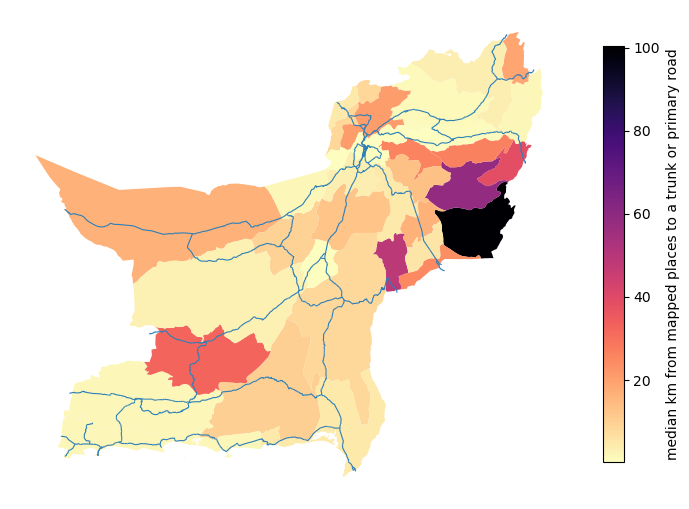

In [12]:
pl = gpd.read_file(DATA / "bal_places.gpkg").to_crs(CRS)
main = roads[roads.highway.isin(["motorway", "trunk", "primary"])]
pl = gpd.sjoin_nearest(pl, main[["geometry"]], distance_col="km").drop_duplicates(subset="geometry")
pl["km"] /= 1000
pl = gpd.sjoin(pl.drop(columns="index_right"), dist[["adm2_name", "geometry"]], predicate="within")
r = pl.groupby("adm2_name").km.agg(["size", "median"]).rename(columns={"size": "mapped places", "median": "median km to main road"})
dist = dist.merge(r, left_on="adm2_name", right_index=True, how="left")
ax = dist.plot("median km to main road", cmap="magma_r", legend=True, figsize=(9, 9), missing_kwds={"color": "#ddd"}, legend_kwds={"label": "median km from mapped places to a trunk or primary road", "shrink": .6})
main.plot(ax=ax, color="#2c7fb8", lw=.8); ax.set_axis_off();

**Is violence near the roads and the extraction sites?** Share of located UCDP events within 5 km of a main road or
10 km of a mapped extraction site, against the share of the province's area within those distances. A share of
events much higher than the share of area means events concentrate there.

In [13]:
ev = gpd.read_file(DATA / "bal_events.gpkg").to_crs(CRS)
ev = ev[ev.where_prec <= 3]
prov = dist.union_all()
for label, zone in [("within 5 km of a main road", main.buffer(5000).union_all()), ("within 10 km of a mapped extraction site", ext.buffer(10000).union_all())]:
    z = zone.intersection(prov)
    print(f"{label}: {ev.within(z).mean():.0%} of events, {z.area / prov.area:.0%} of the province's area")

within 5 km of a main road: 55% of events, 15% of the province's area
within 10 km of a mapped extraction site: 34% of events, 6% of the province's area


**Reading:** 55% of located events lie within 5 km of a main road, which covers 15% of the province; 34% lie
within 10 km of a mapped extraction site, 6% of its area. Lasbela (industrial estates near Karachi) has by far the
most mapped extraction sites; Dera Bugti (gas) and Gwadar (port) combine many sites with many events.
Events are reported where reporters, roads and towns are, so closeness to roads is partly a reporting effect. This
is the kind of result to discuss with people who know the places before writing it up.

## Turning a question into a query: a recipe
1. **Name the thing** you care about (safety, access, belonging, memory, work).
2. **Find a proxy** in the data, and write down what it misses.
3. **Choose the unit** (building, street, cell, neighbourhood) and the distance (straight, walking, time).
4. **Compute, map, compare** with another place or group.
5. **Check against the ground**: interviews, archives, photographs, field visits.
6. **Report the limits** with the result.

**Credits:** © OpenStreetMap contributors (ODbL); Overture Maps Foundation (CDLA-Permissive 2.0 / ODbL);
WorldPop 2020 (CC BY 4.0).